In [238]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [239]:
#Defining initial transmission coefficients, populations and starting values.
a1 = 100   #homo-homo coeff
a2 = 5    #bi infecting homo
b1 = 5    #bi-bi
b2 = b3 = c1 = c2 = d1 = 1   #other infection coefficients
p1 = p2 = 5   #homosexual and bisexual initial populations
q = r = 100    #bi women and hetero men

x1 = 0.01   #number of infected homosexual males
x2 = y = z = 0    #infected bi men, bi women, hetero men

In [240]:
def system(infecs, pops, coeffs, e = 0, deaths = (0,0,0,0)):
    """ 
    Defines the basic system of equations based on the current state, including blood transfusion parameter e and deaths.
    Inputs:
        infecs: tuple, length 4
        pops: tuple, length 4
        coeffs: tuple, length 8
        e: float
    Returns:
        4x1 Numpy array of derivatives [dx1, dx2, dy, dz]
    """

    x1, x2, y, z = infecs
    p1, p2, q, r = pops
    a1, a2, b1, b2, b3, c1, c2, d1 = coeffs
    r1, r2, r3, r4 = deaths

    dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
    dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
    dy = c1 * x2 * (q - y) + c2 * z * (q - y) + e * (q - y) - r3 * y
    dz = d1 * y * (r - z) + e * (r - z) - r4 * z

    return np.array([dx1, dx2, dy, dz])


def fwd_euler(start_infecs, start_pops, coeffs, step_size, end_time, e = 0, frac = False, death = (0,0,0,0)):
    """ 
    Uses Forward Euler Method to simulate infections and populations over time.
    Inputs:
        start_infecs: tuple, length 4. Initial number of infected people in each group.
        start_pops: tuple, length 4. Initial populations of each group.
        coeffs: tuple, length 8. Transmission coefficients between each group.
        step_size: float. Delta time between each iteration. 
        end_time: float. Total amount of time to iterate for.
        e: float. If specified, it is the coefficient describing the effect of blood transfusions.
        frac: boolean. If True, e becomes e times the fraction of total infections.
        death: tuple, length 4. If specified, populations are decreased due to deaths.
    Returns:
        Numpy array of infected populations [x1, x2, y, z] at each time step taken.
    """

    infecs = np.array(start_infecs).astype(float)
    pops = np.array(start_pops).astype(float)
    e1 = e

    h = step_size
    steps = int(end_time / h)
    states = np.zeros((steps, 4))
    deaths = np.array(death).astype(float)
    
    for i in range(steps):
        states[i] = infecs
        if frac:
            e1 = e * np.sum(infecs) / np.sum(pops)
        derivs = system(infecs, pops, coeffs, e1, deaths)
        infecs += h * derivs

    return states


In [241]:
def rk4(start_infecs, start_pops, coeffs, step_size, end_time, e = 0, frac = False, death = (0,0,0,0)):
    """ 
    Uses 4th Order Runge-Kutta (RK4) Method to simulate infections and populations over time.
    Inputs:
        start_infecs: tuple, length 4. Initial number of infected people in each group.
        start_pops: tuple, length 4. Initial populations of each group.
        coeffs: tuple, length 8. Transmission coefficients between each group.
        step_size: float. Delta time between each iteration. 
        end_time: float. Total amount of time to iterate for.
        e: float. If specified, it is the coefficient describing the effect of blood transfusions.
        frac: boolean. If True, e becomes e times the fraction of total infections.
        death: tuple, length 4. If specified, populations are decreased due to deaths.
    Returns:
        Numpy array of infected populations [x1, x2, y, z] at each time step taken.
    """

    infecs = np.array(start_infecs).astype(float)
    pops = np.array(start_pops).astype(float)
    deaths = np.array(death).astype(float)

    h = step_size
    steps = int(end_time / h)
    states = np.zeros((steps, 4))
    
    def get_e1(current_infecs):
        if frac:
            return e * np.sum(current_infecs) / np.sum(pops)
        else:
            return e

    for i in range(steps):
        states[i] = infecs
        
        e1_1 = get_e1(infecs)
        k1 = system(infecs, pops, coeffs, e1_1, deaths)
        
        infecs_k2 = infecs + 0.5 * h * k1
        e1_2 = get_e1(infecs_k2)
        k2 = system(infecs_k2, pops, coeffs, e1_2, deaths)
        
        infecs_k3 = infecs + 0.5 * h * k2
        e1_3 = get_e1(infecs_k3)
        k3 = system(infecs_k3, pops, coeffs, e1_3, deaths)
        
        infecs_k4 = infecs + h * k3
        e1_4 = get_e1(infecs_k4)
        k4 = system(infecs_k4, pops, coeffs, e1_4, deaths)
        
        infecs += (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

    return states

C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: overflow encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: overflow encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: invalid value encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:20: RuntimeWarning: overflow encountered in scalar multiply
  dy = c1 * x2 * (q - y) + c2

Text(0.02, 0.5, 'Number of infections')

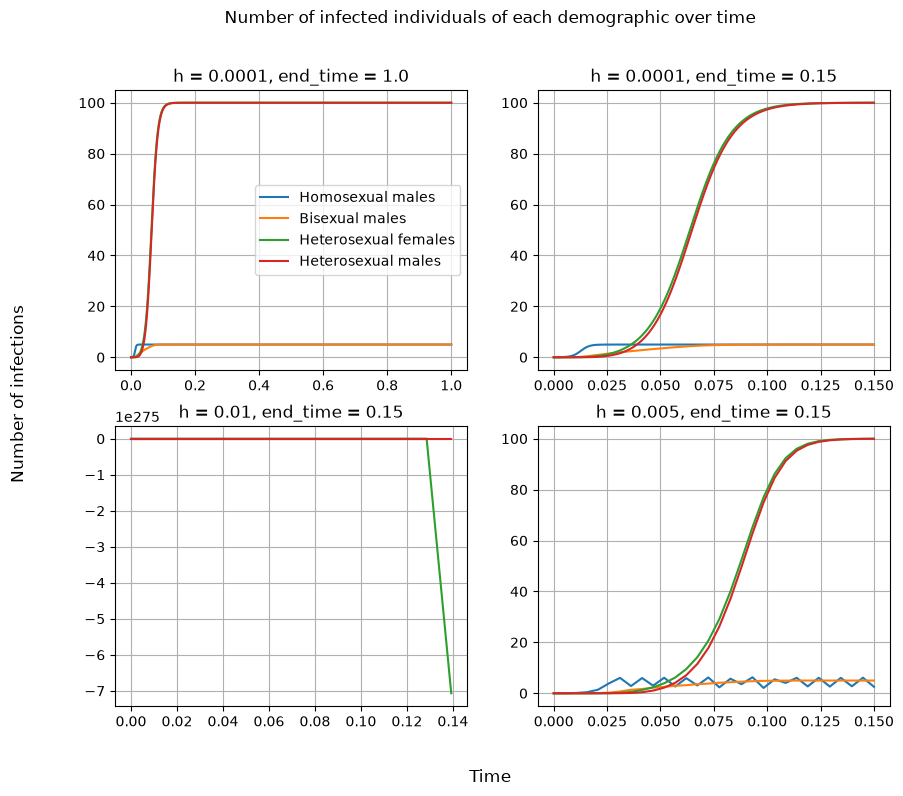

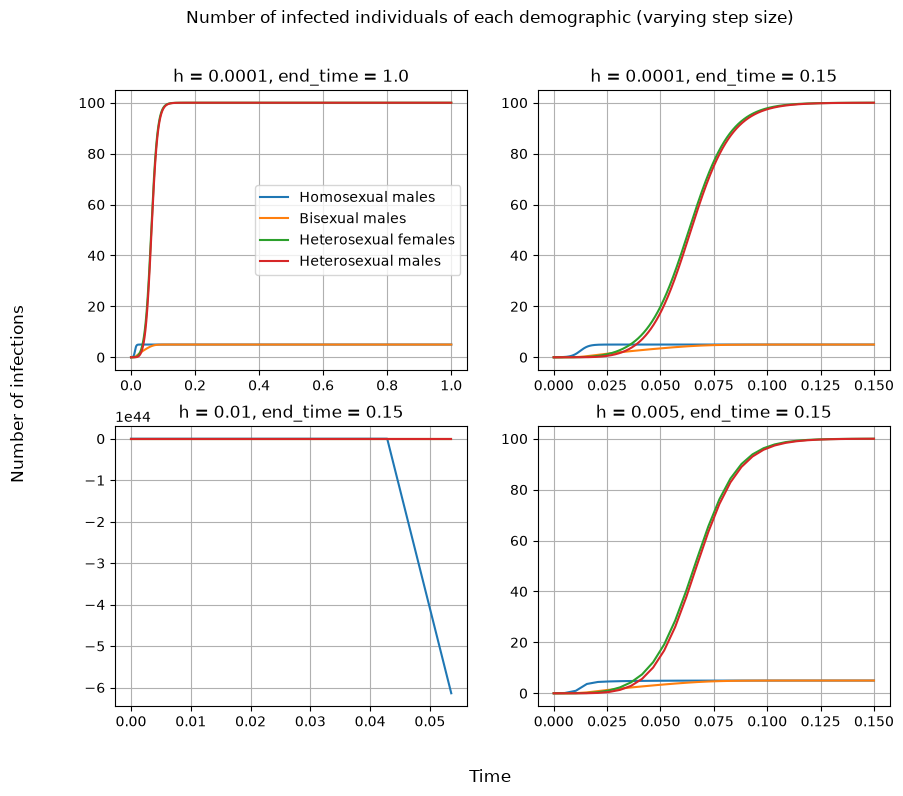

In [242]:
#Creating plots to initially investigate the required time scale and step size using Euler's Method. 
start_infecs1 = (x1, x2, y, z)
start_pops1 = (p1, p2, q, r)
coeffs1 = (a1, a2, b1, b2, b3, c1, c2, d1)

steps_ends = [
    (0.0001, 1.0),
    (0.0001, 0.15),
    (0.01,   0.15),
    (0.005,  0.15)]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, (h, end_time) in zip(axes.flat, steps_ends):
    data = fwd_euler(start_infecs1, start_pops1, coeffs1, h, end_time)
    timestamps = np.linspace(0, end_time, int(end_time / h))
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'h = {h}, end_time = {end_time}')
    ax.grid()

fig.suptitle('Number of infected individuals of each demographic over time')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')


steps_ends2 = [
    (0.0001, 1.0),
    (0.0001, 0.15),
    (0.01,   0.15),
    (0.005,  0.15)]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, (h, end_time) in zip(axes.flat, steps_ends2):
    data = rk4(start_infecs1, start_pops1, coeffs1, h, end_time)
    timestamps = np.linspace(0, end_time, int(end_time / h))
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'h = {h}, end_time = {end_time}')
    ax.grid()

fig.suptitle('Number of infected individuals of each demographic (varying step size)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')

First, we use the forward Euler method. We first run the simulation for various step sizes and end points to get a sense of the time scale of the problem and stability of the method. We initially use  very small step size of h = 0.0001 to ensure stability and an end time of 1 (arbitrary units). Clearly the system reaches equilibrium very fast. So, from now on we use an end time of 0.15, the data for which is shown in the top-right plot. Having checked this against small step sizes in RK4, we can consider this to be a realistic plot. 

Next we look at a step size of h = 0.01. Clearly the method becomes completely unstable at this step size. We next look at an intermediate step size of h = 0.005. The curves have the correct general shape, but there are two issues: one is the curve for the homosexual male demographic becomes jagged, since the step size is slightly too big to find the equilibrium, so each iteration bounces around this equilibrium point. The second is that the curves for heterosexual males and females reaches its equilibrium later than it does in the graph above it. This is interesting, because even though at first glance we have a stable step size which produces the correct shape, we lose significant accuracy.

We will now analyse the effect of step size on accuracy and stability comparing Euler and RK4. We will zoom in to the curve for homosexual males and heterosexual males, as these have different time scales, and plot different step sizes against each other. 

C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: overflow encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: overflow encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: invalid value encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:20: RuntimeWarning: overflow encountered in scalar multiply
  dy = c1 * x2 * (q - y) + c2

Text(0.02, 0.5, 'Number of infections')

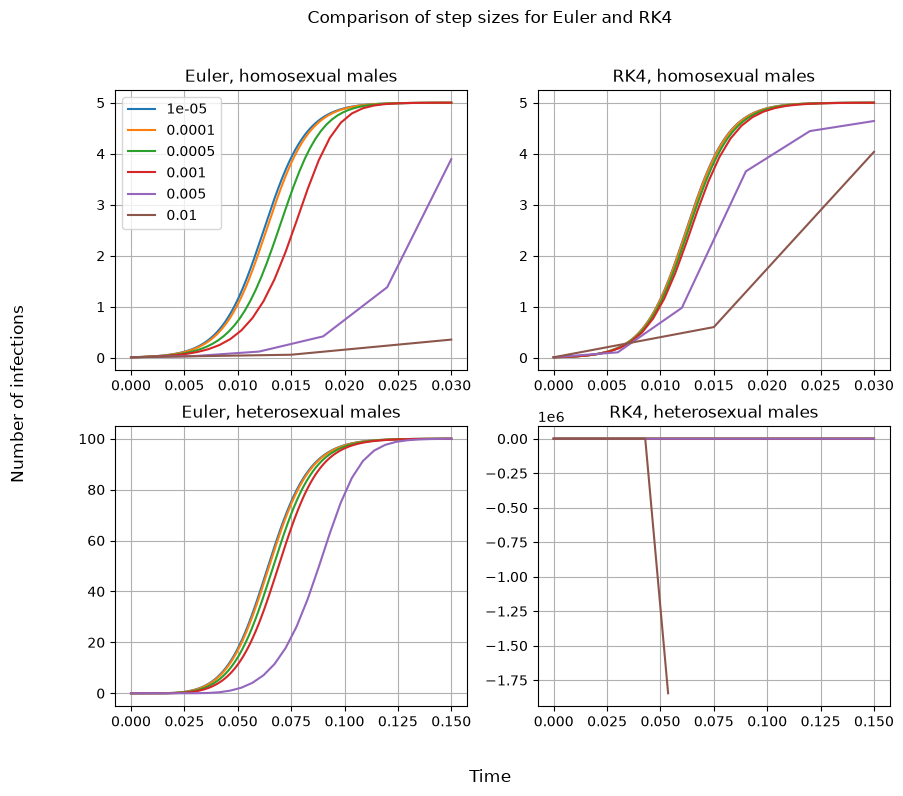

In [243]:
#Creating plots for homo- and heterosexual males, using different step sizes for Euler and RK4 methods
step_sizes = [0.00001, 0.0001, 0.0005, 0.001, 0.005, 0.01]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']
ax1 = axes[0,0]
ax2 = axes[0,1]
ax3 = axes[1,0]
ax4 = axes[1,1]

for i, h in enumerate(step_sizes):
    data = fwd_euler(start_infecs1, start_pops1, coeffs1, h, 0.03)[:,0]
    timestamps = np.linspace(0, 0.03, int(0.03/h))
    ax1.plot(timestamps, data, label = h)
    ax1.grid(True)
    ax1.legend()
    ax1.set_title('Euler, homosexual males')

for i, h in enumerate(step_sizes):
    data = rk4(start_infecs1, start_pops1, coeffs1, h, 0.03)[:,0]
    timestamps = np.linspace(0, 0.03, int(0.03/h))
    ax2.plot(timestamps, data, label = h)
    ax2.grid(True)    
    ax2.set_title('RK4, homosexual males')


for i, h in enumerate(step_sizes):
    if h == 0.01:
        continue
    data = fwd_euler(start_infecs1, start_pops1, coeffs1, h, 0.15)[:,3]
    timestamps = np.linspace(0, 0.15, int(0.15/h))
    ax3.plot(timestamps, data, label = h)
    ax3.grid(True)
    ax3.set_title('Euler, heterosexual males')


for i, h in enumerate(step_sizes):
    data = rk4(start_infecs1, start_pops1, coeffs1, h, 0.15)[:,3]
    timestamps = np.linspace(0, 0.15, int(0.15/h))
    ax4.plot(timestamps, data, label = h)
    ax4.grid(True)
    ax4.set_title('RK4, heterosexual males')

fig.suptitle('Comparison of step sizes for Euler and RK4')
fig.supxlabel('Time')
fig.supylabel('Number of infections')


First we examine the top-left plot. For h = 0.005 (the same as our final subplot earlier), we see the issue become much clearer once zoomed in. For h = 0.001 and h = 0.0005, we have a significant increase in accuracy, well worth doing an extra 5-10x the amount of iterations for. Since this scale is very zoomed in, this may be accurate enough, especially if our characteristic time scale increases or if computations become more expensive. For h = 0.0001 and less, the increase in accuracy becomes very small, even at this small time scale. Since computations are fast, we can consider a step size of h = 0.0001 to be accurate enough for the forward Euler Method. 

For the bottom-left plot, these step sizes seem more accurate because the time-scale is bigger. For h = 0.01, however, we couldn't plot this value because it blew up so much that the plot became nonsensical. For the RK4 plots, on the other hand, h = 0.01 is inaccurate but is still stable. Even if we  h = 0.05, it takes a lot longer, but RK4 eventually reaches the correct equilibrium points. In general RK4 is clearly much more stable and accurate ($O(h^4)$ accuracy instead of $O(h)$). Even for step sizes so large that we can see the jumps at this time scale, RK4 is able to produce semi-consistent results. We can consider the accuracy of h = 0.001 to be sufficient for RK4. For a similar amount of accuracy, RK4 requires 10x less steps than Euler, albeit needing 4 points per step instead of 1. We will now analyse the speeds of each method.

In [244]:
#Timing RK4 and Fwd Euler
%timeit fwd_euler(start_infecs1, start_pops1, coeffs1, 0.001, 0.15)
%timeit rk4(start_infecs1, start_pops1, coeffs1, 0.001, 0.15)
%timeit fwd_euler(start_infecs1, start_pops1, coeffs1, 0.0001, 0.15)
%timeit rk4(start_infecs1, start_pops1, coeffs1, 0.0001, 0.15)

2.64 ms ± 1.49 ms per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
7.05 ms ± 238 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
15.9 ms ± 422 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
74.5 ms ± 5.75 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


As expected, for the same step size RK4 is 5x slower than Euler, due to the intermediate steps. However, if we include that our step size can be 10x smaller for RK4, it actually becomes 2x faster. When we combine this with the added stability, RK4 seems to be the favorable method.

Next, we vary the starting values to examine the effects on the system.

Text(0.02, 0.5, 'Number of infections')

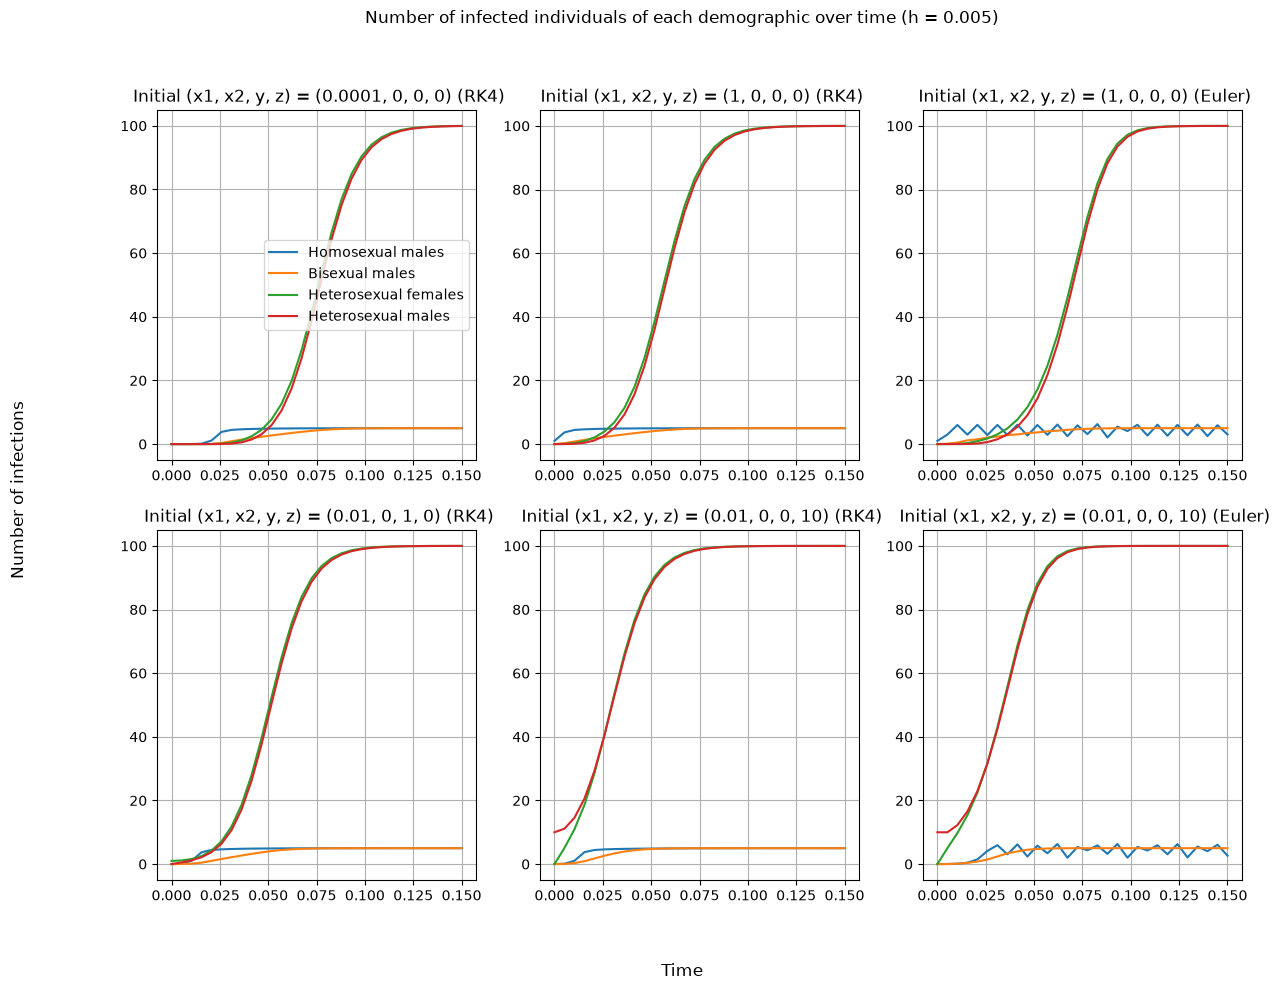

In [245]:
#we reiterate the coefficient values as a reminder
a1 = 100   #homo-homo coeff
a2 = 5    #bi infecting homo
b1 = 5    #bi-bi
b2 = b3 = c1 = c2 = d1 = 1   #other infection coefficients
p1 = p2 = 5   #homosexual and bisexual initial populations
q = r = 100    #bi women and hetero men

x1 = 0.01   #number of infected homosexual males
x2 = y = z = 0    #infected bi men, bi women, hetero men

start_infecs1 = (x1, x2, y, z)
start_pops1 = (p1, p2, q, r)
coeffs1 = (a1, a2, b1, b2, b3, c1, c2, d1)

start_infecs_list = [
    (0.0001, x2, y, z),
    (1, x2, y, z),
    (1, x2, y, z),
    (x1, x2, 1, z),
    (x1, x2, y, 10),
    (x1, x2, y, 10) ]

# plots comparing RK4 and Euler, changing starting values
fig, axes = plt.subplots(2, 3, figsize=(14, 10))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, start_infec in zip(axes.flat, start_infecs_list):
    data = rk4(start_infec, start_pops1, coeffs1, 0.005, 0.15)
    timestamps = np.linspace(0, 0.15, int(0.15 / 0.005))
    ax.set_title(f' Initial (x1, x2, y, z) = {start_infec} (RK4)')
    if ax == axes[0,2] or ax == axes[1,2]:
        data = fwd_euler(start_infec, start_pops1, coeffs1, 0.005, 0.15)
        ax.set_title(f' Initial (x1, x2, y, z) = {start_infec} (Euler)')

    ax.plot(timestamps, data, label=labels)
    
    ax.grid()

fig.suptitle('Number of infected individuals of each demographic over time (h = 0.005)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')

The plots in the leftmost two columns use RK4 with h = 0.005 and the rightmost column uses Forward Euler with h = 0.005, to compare to RK4. 

In the two top-rightmost plots, we first decrease x1 (infected homosexual males) by a factor of 100 and then increase it by a factor of 100, relative to the starting value of x1 = 0.01. Perhaps trivially, but crucially, the equilibria values remain the same. We see that the population of homosexual males follows nearly the same shape of curve, but it begins earlier for a higher starting value, so it reaches equilibrium much earlier. Interestingly, the other curves have almost no discernable difference in shape for different x1 values. The time they reach equilibrium also doesn't change as much as one might expect. This could likely be because the values for y and z aren't directly affected by x1, and even the impact for x2 is mild since the population of homosexual males is relatively low. Additionally, once x1 reaches equilibrium, its contribution remains constant. 

In the bottom-left two plots, we set y0 = 1 and z0 = 10, respectively. We see that y and z reach equilibrium earlier, as one would expect. They still reach equilibrium at around the same time as each other though, since their derivatives and therefore curves are still very much linked to each other. x2 reaches equilibrium slightly faster for z0 = 10, as it is a far greater starting value than y0 = 1, but there is very little difference for x1. This is likely because the infections for z need to travel through y, then x2 and then to x1, where it plays an increasingly small role. Then it is slightly damped for x2, explaining the small difference, and very damped for x1, explaining the almost non-existent difference. 

If one plots the same data with Forward Euler with h = 0.0001, we get the same results as for RK4, as one would expect. If we instead increase to h = 0.001, we get underestimates for each step (because the slope is increasing, and we estimate the slope from the start of the interval) and thus equilibrium appears to be reached later. In the plots in the rightmost column we have plotted using Forward Euler for h = 0.005 so emphasize the difference. Notably, in the bottom-right plot, the underestimate isn't as large, perhaps because the slope already starts out nearer to its maximum value. We also see that the step size is too large for x1 to settle on an equilibrium. 

C:\Users\danie\AppData\Local\Temp\ipykernel_7052\540100813.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0,0].legend()


Text(0.02, 0.5, 'Number of infections, x1')

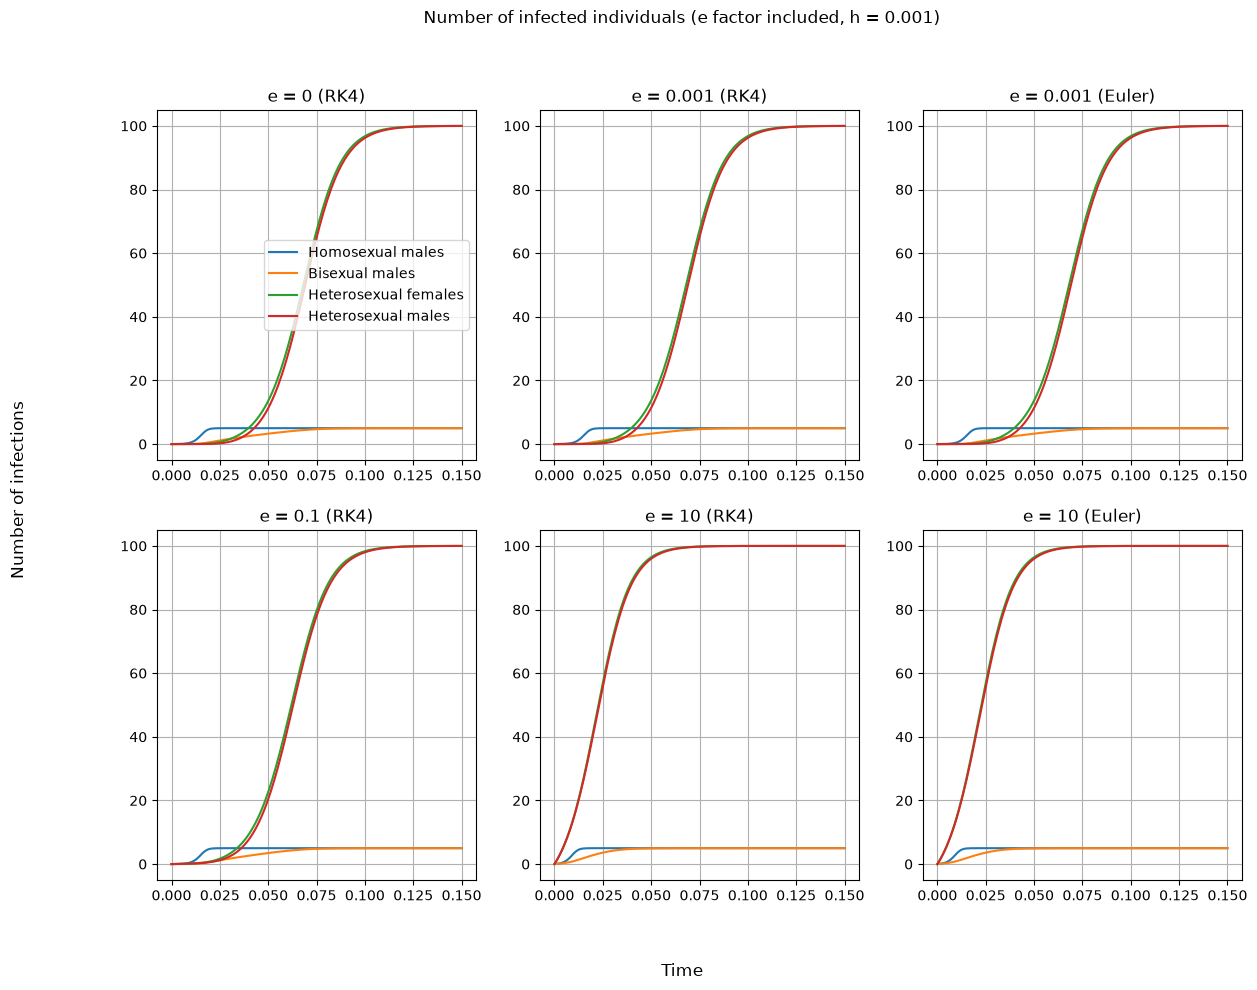

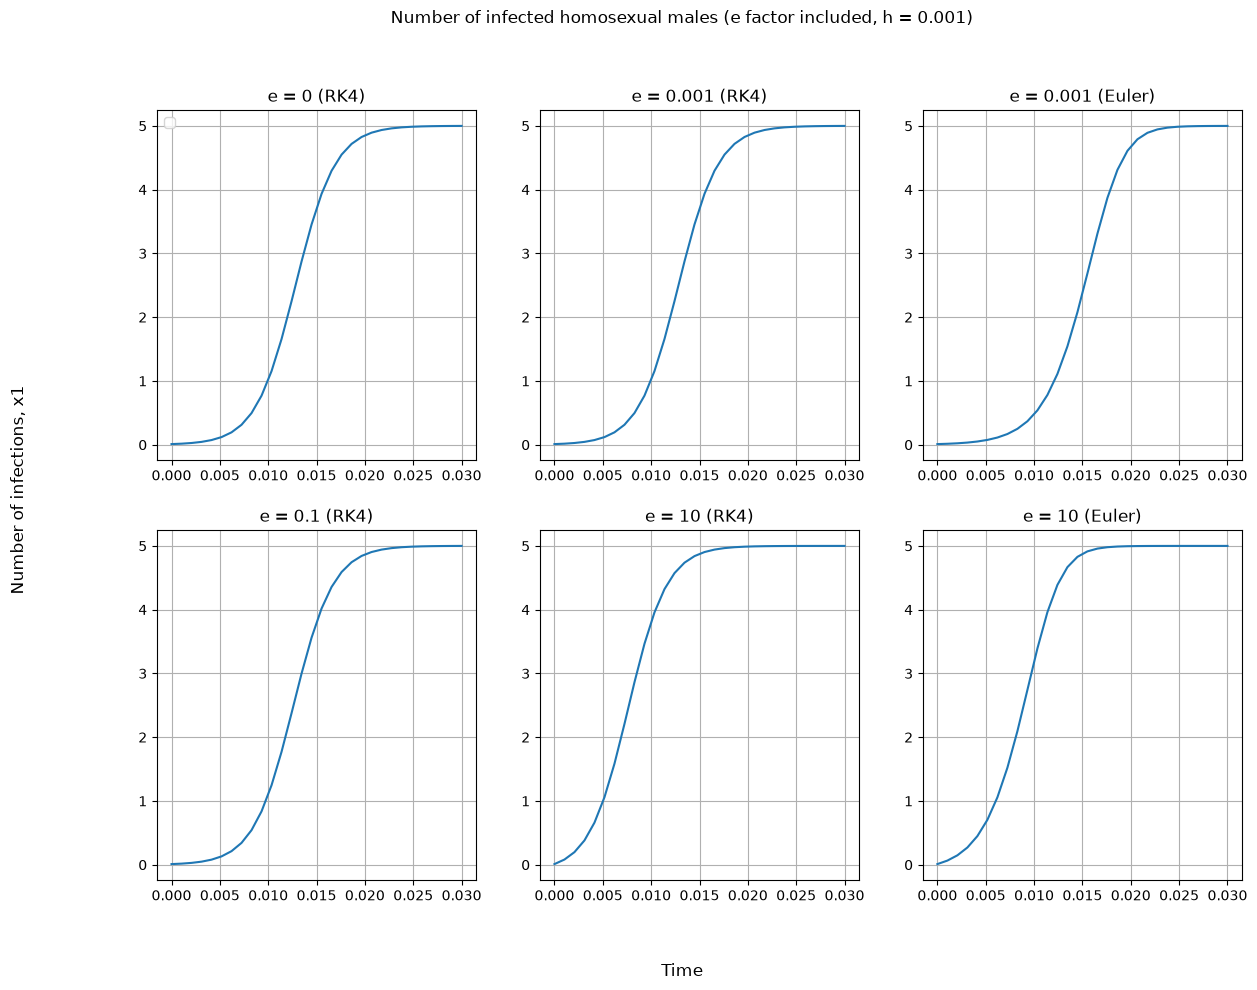

In [246]:
a1 = 100   #homo-homo coeff
a2 = 5    #bi infecting homo
b1 = 5    #bi-bi
b2 = b3 = c1 = c2 = d1 = 1   #other infection coefficients
p1 = p2 = 5   #homosexual and bisexual initial populations
q = r = 100    #bi women and hetero men

x1 = 0.01   #number of infected homosexual males
x2 = y = z = 0    #infected bi men, bi women, hetero men

start_infecs1 = (x1, x2, y, z)
start_pops1 = (p1, p2, q, r)
coeffs1 = (a1, a2, b1, b2, b3, c1, c2, d1)
e_list = [0, 0.001, 0.001, 0.1, 10, 10]

#full plots, including e
fig, axes = plt.subplots(2, 3, figsize=(14, 10))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, e in zip(axes.flat, e_list):
    data = fwd_euler(start_infecs1, start_pops1, coeffs1, 0.001, 0.15, e)
    timestamps = np.linspace(0, 0.15, int(0.15 / 0.001))
    ax.set_title(f'e = {e} (RK4)')
    if ax == axes[0,2] or ax == axes[1,2]:
        data = fwd_euler(start_infecs1, start_pops1, coeffs1, 0.001, 0.15, e)
        ax.set_title(f'e = {e} (Euler)')
    ax.plot(timestamps, data, label=labels)
    
    ax.grid()

fig.suptitle('Number of infected individuals (e factor included, h = 0.001)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')

#plots of just x1, including e
fig, axes = plt.subplots(2, 3, figsize=(14, 10))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, e in zip(axes.flat, e_list):
    data = rk4(start_infecs1, start_pops1, coeffs1, 0.001, 0.03, e)[:,0]
    timestamps = np.linspace(0, 0.03, int(0.03 / 0.001))
    ax.set_title(f'e = {e} (RK4)')
    if ax == axes[0,2] or ax == axes[1,2]:
        data = fwd_euler(start_infecs1, start_pops1, coeffs1, 0.001, 0.03, e)[:,0]
        ax.set_title(f'e = {e} (Euler)')
    ax.plot(timestamps, data)
    ax.grid()

fig.suptitle('Number of infected homosexual males (e factor included, h = 0.001)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections, x1')


We now added the effects of blood tranfusions with the prefactor e. Blood transfusions can be thought of as a driving force added to the system which is proportional to the number of uninfected people in a population. Therefore it causes the rate of infection to increase, especially at the start when there are many uninfected people. As we increase e in the plots above, the curves start to increase earlier and faster. Their slope at the start is much steeper, but the maximum steepness doesn't increase much, likely because other terms begin to dominate at this point. 

We have also used Forward Euler to compare it to RK4, this time using step sizes of h = 0.001 for both. At this step size, the difference is much less noticable for the main plots. If we zoom into just the plots for x1, we see the difference more clearly. Once again, Forward Euler underestimates the slope, and is therefore perpetually 'behind'. For the system in general, these plots also illustrate the increased acceleration of viral spread well - we see the virus spread faster at first, and then at a similar rate to before. We find the same equilibrium points, but they are reached earlier. 

Text(0.02, 0.5, 'Number of infections')

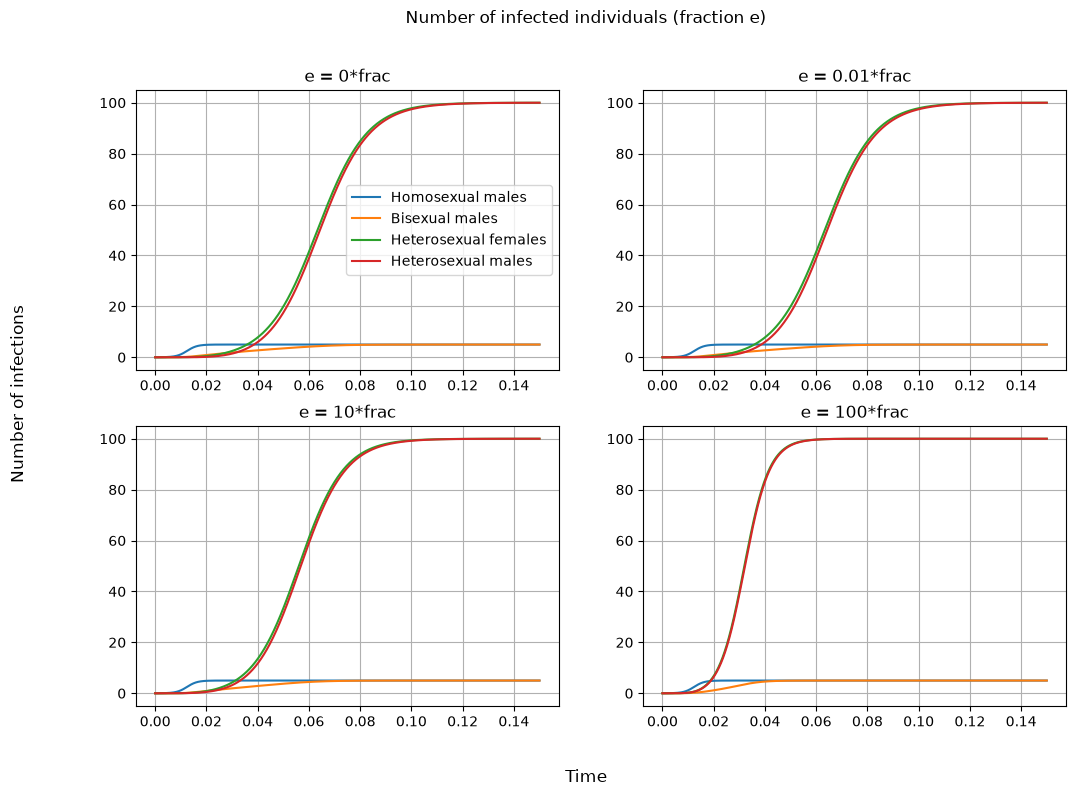

In [247]:
#plotting with e as a fraction of total infected population
start_infecs1 = (x1, x2, y, z)
start_pops1 = (p1, p2, q, r)
coeffs1 = (a1, a2, b1, b2, b3, c1, c2, d1)
e_list = [0, 0.01, 10, 100]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, e in zip(axes.flat, e_list):
    data = rk4(start_infecs1, start_pops1, coeffs1, 0.0001, 0.15, e, True)
    timestamps = np.linspace(0, 0.15, int(0.15 / 0.0001))
    
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'e = {e}*frac')
    ax.grid()

fig.suptitle('Number of infected individuals (fraction e)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')

We now change e so that it is multiplied by the proportion of total infections in the total population. This is more realistic, since a higher number of infections in the total population will increase the likelihood of a blood tranfusion infection occuring. Multiplying by this fraction decreases the effect of e, so the top-right plot of e = 0.01 * frac has almost no difference. Only once we near 10 and 100 do we see noticeable differences. We end up having a steeper slope, particularly as the total number of infections increase. At the start, when the total infections is low, the slope doesn't rise nearly as fast as for the fixed e values. If we plot with Euler's Method instead, we find the same patterns as previously, so we have omitted these plots.

Finally, we complete the model by incorporating deaths, where we will find the most interesting results.

Text(0.02, 0.5, 'Number of infections')

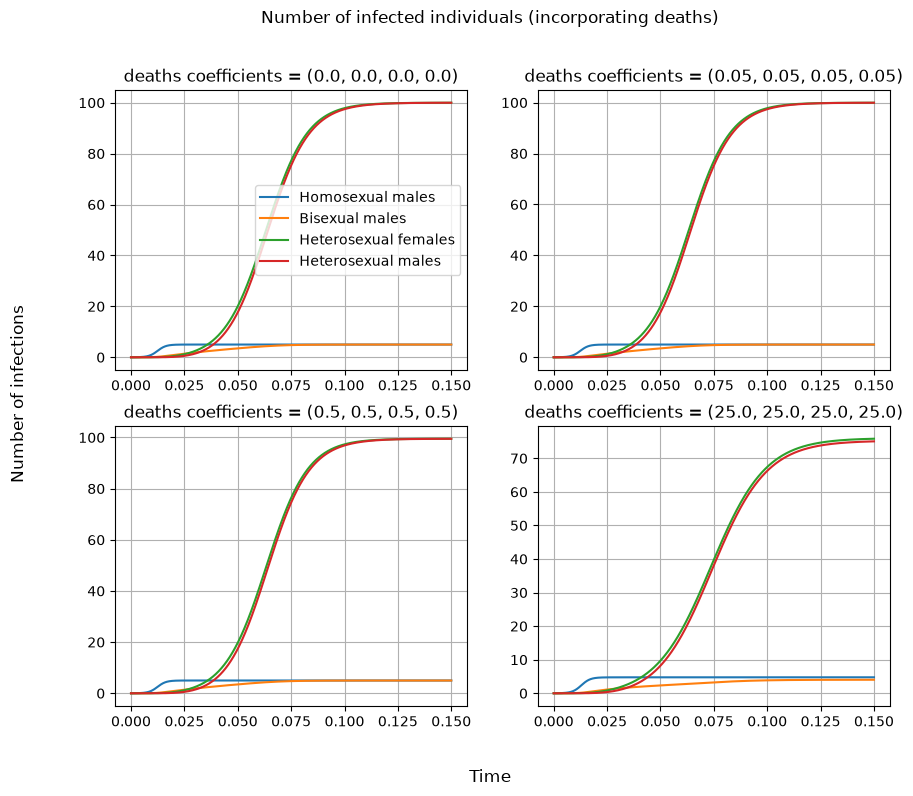

In [248]:
#Code for plotting with deaths included
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']
death_coeff_list = [
    (0.0,0.0,0.0,0.0),
    (0.05,0.05,0.05,0.05),
    (0.5,0.5,0.5,0.5),
    (25.0,25.0,25.0,25.0)
]

for ax, death_coeff in zip(axes.flat, death_coeff_list):
    data = rk4(start_infecs1, start_pops1, coeffs1, 0.00001, 0.15, 0.01, True, death_coeff)
    timestamps = np.linspace(0, 0.15, int(0.15 / 0.00001))
    
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'deaths coefficients = {death_coeff}')
    ax.grid()

fig.suptitle('Number of infected individuals (incorporating deaths)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')

Now we have included the effect of deaths on the population of infected individuals. The overall populations remain the same. For low death coefficients, we see minimal difference. The equilibrium is very slightly lower and is reached very slightly later. Only once we increase the coefficients to 25, an absurdly large value, do we see a noticable decrease in equilibrium, caused by a lower total population of infected people. For more realistic results, we assume that deaths do impact the total population.

In [249]:
def fwd_euler_popdeaths(start_infecs, start_pops, coeffs, step_size, end_time, e = 0, frac = False, death = (0,0,0,0)):
    """ 
    Uses Forward Euler Method to simulate infections and populations over time,
    including the effects of deaths in the total population.
    Inputs:
        start_infecs: tuple, length 4. Initial number of infected people in each group.
        start_pops: tuple, length 4. Initial populations of each group.
        coeffs: tuple, length 8. Transmission coefficients between each group.
        step_size: float. Delta time between each iteration. 
        end_time: float. Total amount of time to iterate for.
        e: float. If specified, it is the coefficient describing the effect of blood transfusions.
        frac: boolean. If True, e becomes e times the fraction of total infections.
        death: tuple, length 4. If specified, populations are decreased due to deaths.
    Returns:
        Numpy array of infected populations [x1, x2, y, z] at each time step taken.
    """

    infecs = np.array(start_infecs).astype(float)
    pops = np.array(start_pops).astype(float)
    e1 = e

    h = step_size
    steps = int(end_time / h)
    states = np.zeros((steps, 4))
    deaths = np.array(death).astype(float)
    pop_states = np.zeros((steps, 4))
    
    for i in range(steps):
        states[i] = infecs
        pop_states[i] = pops
        if frac:
            e1 = e * np.sum(infecs) / np.sum(pops)
        derivs = system(infecs, pops, coeffs, e1, deaths)
        infecs += h * derivs
        infecs = np.clip(infecs, a_min=0, a_max = pops)
        pops -= deaths * infecs
        pops = np.clip(pops, a_min=0, a_max=start_pops)

    return states, pop_states


C:\Users\danie\AppData\Local\Temp\ipykernel_7052\845699024.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  e1 = e * np.sum(infecs) / np.sum(pops)
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: invalid value encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:20: RuntimeWarning: invalid value encountered in scalar multiply
  dy = c1 * x2 * (q - y) + c2 * z * (q - y) + e * (q - y) - r3 * y


Text(0.02, 0.5, 'Population size')

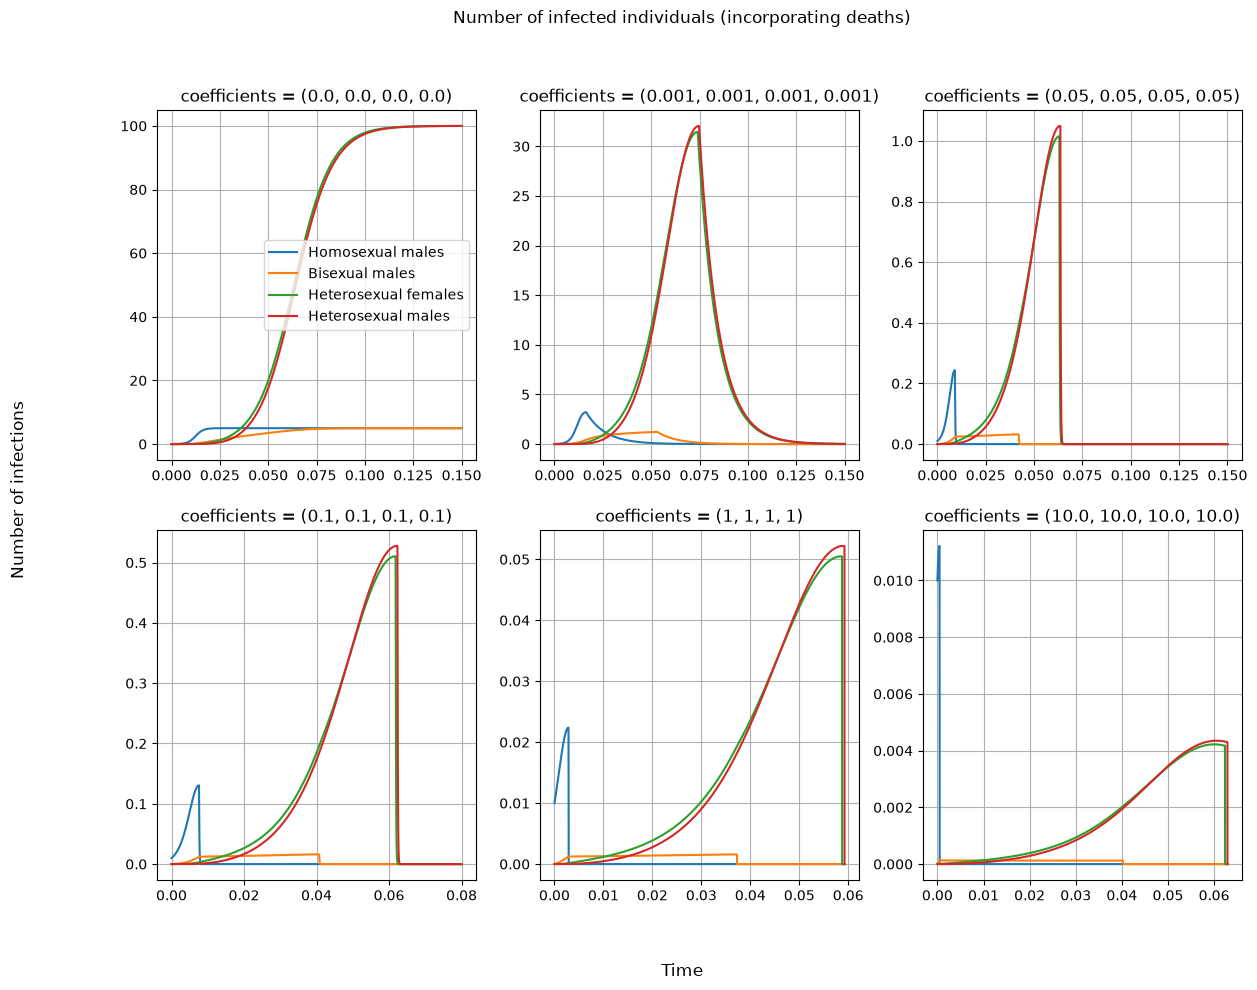

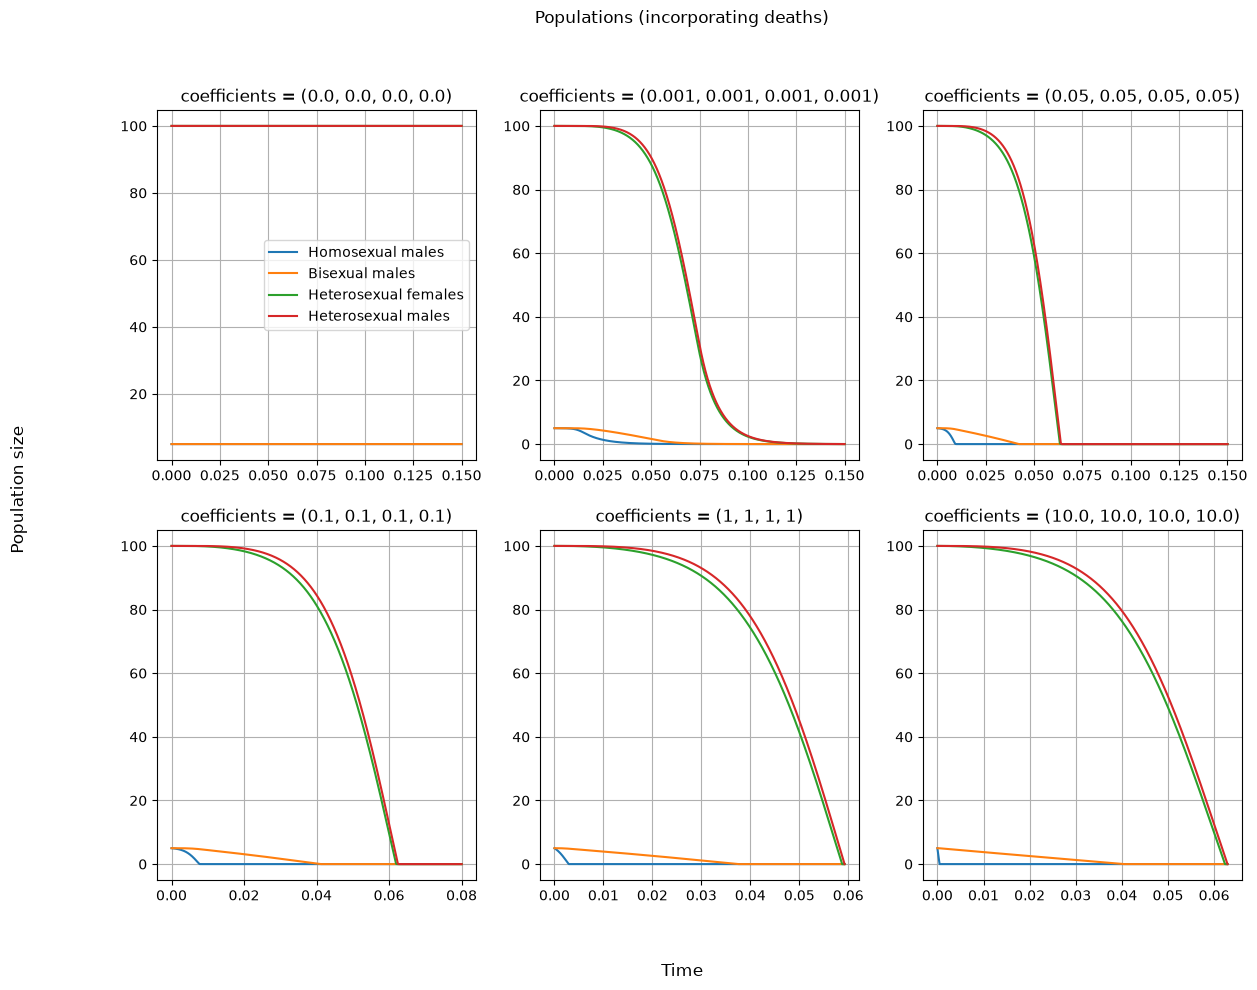

In [250]:
fig, axes = plt.subplots(2, 3, figsize=(14, 10))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']
death_coeff_list = [
    (0.0,0.0,0.0,0.0),
    (0.001, 0.001, 0.001, 0.001),
    (0.05,0.05,0.05,0.05),
    (0.1,0.1,0.1,0.1),
    (1,1,1,1),
    (10.0,10.0,10.0,10.0)
]
end_times = [0.15, 0.15, 0.15, 0.08, 0.08, 0.08]

for ax, death_coeff, end in zip(axes.flat, death_coeff_list, end_times):
    data = fwd_euler_popdeaths(start_infecs1, start_pops1, coeffs1, 0.00001, end, 0.01, True, death_coeff)[0]
    timestamps = np.linspace(0, end, int(end / 0.00001))
    
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'coefficients = {death_coeff}')
    ax.grid()

fig.suptitle('Number of infected individuals (incorporating deaths)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of infections')

fig, axes = plt.subplots(2, 3, figsize=(14, 10))


for ax, death_coeff, end in zip(axes.flat, death_coeff_list, end_times):
    data = fwd_euler_popdeaths(start_infecs1, start_pops1, coeffs1, 0.00001, end, 0.01, True, death_coeff)[1]
    timestamps = np.linspace(0, end, int(end / 0.00001))
    
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'coefficients = {death_coeff}')
    ax.grid()

fig.suptitle('Populations (incorporating deaths)')
axes[0,0].legend()
fig.supxlabel('Time')
fig.supylabel('Population size')


Now we have rewritten the Forward Euler Method function to include the effects of death on the overall population. In the first set of plots, we see the effects on the number of infected individuals. We now get very interesting results, as the number of infections begins to rise, hits a peak and then decreases to 0. This is because, at the peak, the overall populations have decreased to under 50% of their original values, so the people that can be infected also decrease, while those already infected start to die off until everyone is deceased. In all these plots, the new equilibrium points are all at 0. To extend this model further, we could incorporate the effects of infected people getting better, immunity and vaccinations. 

As the death coefficients are increased, the peaks are reached slightly earlier, and populations die off slightly faster (although less than one might expect). We see the fastest spike and earliest extinction in the group of homosexual males, as the infections start there and spread fastest through their group. If we change these initial parameters, other groups die off faster and sooner as one would expect. The group of infected bisexual males reaches an equilibrium for a moment, starting at the point where the homosexual males have gone extinct, likely because there are now less people to infect them. Then later, they do die off. This is a good lesson against stopping your end time too early. Interestingly, for the death coefficients of 10, the hetero groups die off slightly slower. A possible explanation is that the homosexual males die off so fast that they barely have time to infect the other groups.

In the second set of plots we have the total populations. These fall off as one would expect. Even a small death coefficient of 0.001 has a profound impact on population declines - a valuable insight for the real world. 

C:\Users\danie\AppData\Local\Temp\ipykernel_7052\845699024.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  e1 = e * np.sum(infecs) / np.sum(pops)
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: invalid value encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:20: RuntimeWarning: invalid value encountered in scalar multiply
  dy = c1 * x2 * (q - y) + c2 * z * (q - y) + e * (q - y) - r3 * y


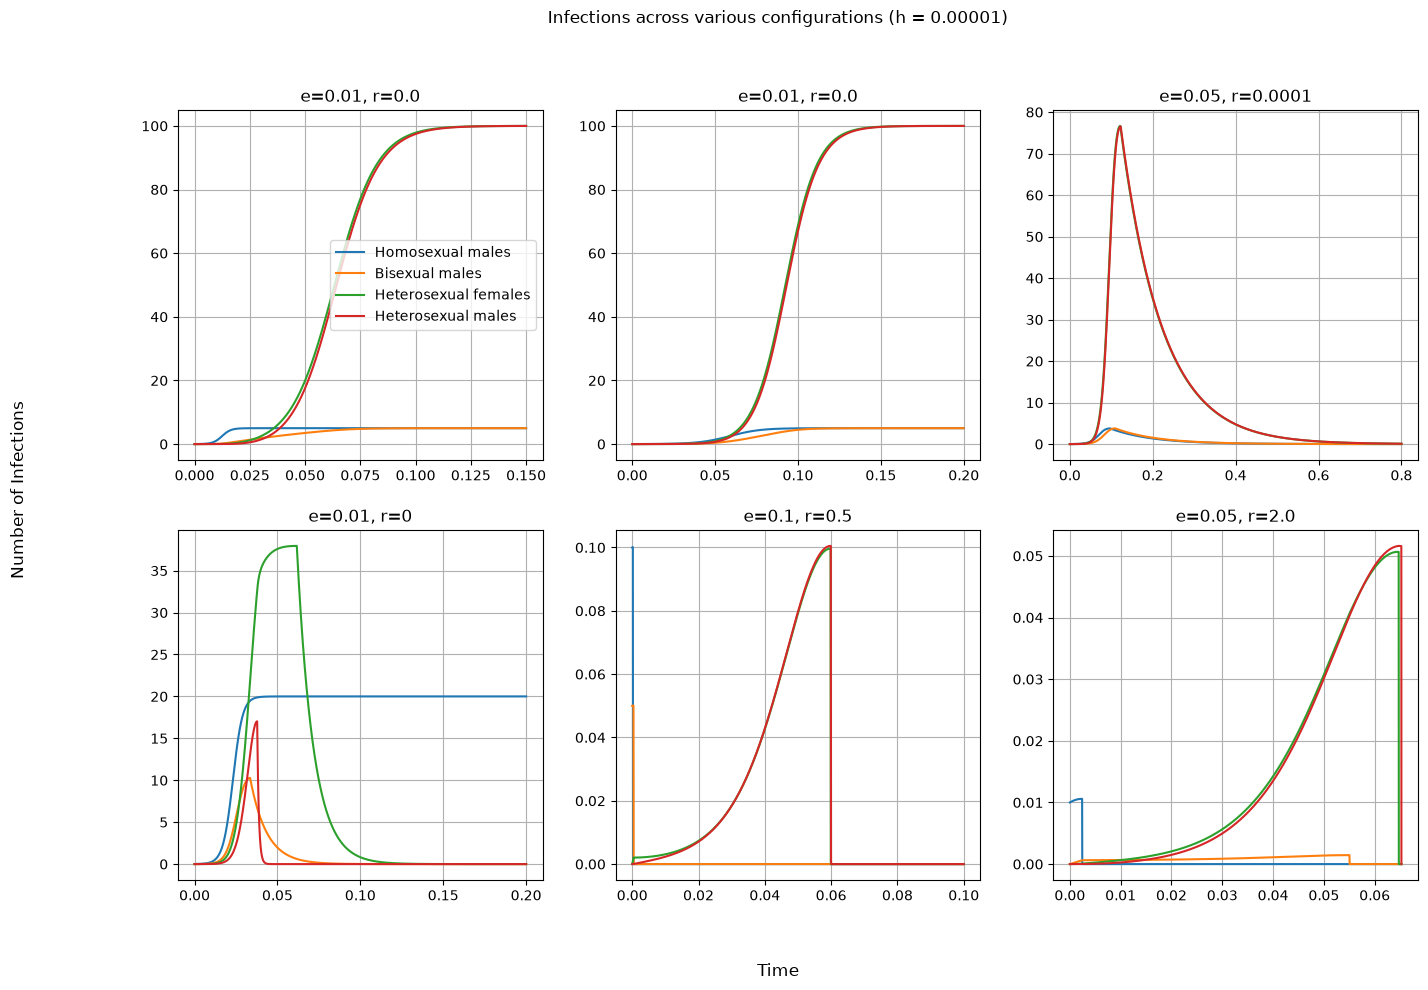

In [251]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

coeffs_list = [
    (100, 5, 5, 1, 1, 1, 1, 1),
    (20, 5, 5, 1, 1, 1, 1, 1),
    (15, 8, 5, 2, 1, 1, 1, 1),
    (15, 5, 5, 1, 1, 1, 1, 1),
    (15, 5, 5, 1, 1, 1, 1, 1),
    (10, 5, 5, 1, 1, 1, 1, 1)]

pops_list = [
    (5, 5, 100, 100),
    (5, 5, 100, 100),
    (5, 5, 100, 100),
    (20, 20, 150, 150),
    (1, 1, 100, 100),
    (5, 5, 100, 100) 
]

start_infecs_list = [
    (0.01, 0.0, 0.0, 0.0), 
    (0.01, 0.0, 0.0, 0.0), 
    (0.01, 0.0, 0.0, 0.0), 
    (0.01, 0.0, 0.0, 0.0),      
    (0.1, 0.05, 0.0, 0.0), 
    (0.01, 0.0, 0.0, 0.0) 
]

death_coeff_list = [
    (0.0, 0.0, 0.0, 0.0), 
    (0.0, 0.0, 0.0, 0.0),
    (0.0001, 0.0001, 0.0001, 0.0001),   #small death coefficients
    (0, 0.001, 0.001, 0.010),    #a world where gay men are invincible
    (0.5, 0.5, 0.5, 0.5),
    (2.0, 1.0, 1.0, 1.0)]

end_times = [0.15, 0.2, 0.8, 0.2, 0.1, 0.1] 
e_list = [0.01, 0.01, 0.05, 0.01, 0.1, 0.05]

for ax, coeffs, start_pops, start_infecs, death_coeff, end, e_val in zip(
    axes.flat, coeffs_list, pops_list, start_infecs_list, death_coeff_list, end_times, e_list):
    step_size = 0.00001
    data = fwd_euler_popdeaths(start_infecs, start_pops, coeffs, step_size, end, e_val, True, death_coeff)[0]
    
    timestamps = np.linspace(0, end, len(data))
    
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'e={e_val}, r={death_coeff[0]}')
    ax.grid(True)

fig.suptitle('Infections across various configurations (h = 0.00001)')
axes[0, 0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of Infections')
plt.show()

Now we have tried some various values for starting configurations, transmission coefficients, e values and death values. We have also changed them for different populations. For instance, perhaps the most interesting looking plot is in the bottom left, where homosexual males have a population of 20, and are invincible. This is why their equilibrium sits at 20. The other populations still get increasingly infected and die out as expected. For the top-right plot, we have very small death coefficients, which is why most people in the population can get infected before very slowly dying out. 

Before this, we have been trying to change just one variable at a time so say something about it. Now, we have changed multiple parameters simultaneously, so we cannot conclude a huge amount about each of these graphs. 

C:\Users\danie\AppData\Local\Temp\ipykernel_7052\845699024.py:32: RuntimeWarning: divide by zero encountered in scalar divide
  e1 = e * np.sum(infecs) / np.sum(pops)
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:18: RuntimeWarning: invalid value encountered in scalar multiply
  dx1 = a1 * x1 * (p1 - x1) + a2 * x2 * (p1 - x1) + e * (p1 - x1) - r1 * x1
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  dx2 = b1 * x1 * (p2 - x2) + b2 * x2 * (p2 - x2) + b3 * y * (p2 - x2) + e * (p2 - x2) - r2 * x2
C:\Users\danie\AppData\Local\Temp\ipykernel_7052\3418127045.py:20: RuntimeWarning: invalid value encountered in scalar multiply
  dy = c1 * x2 * (q - y) + c2 * z * (q - y) + e * (q - y) - r3 * y


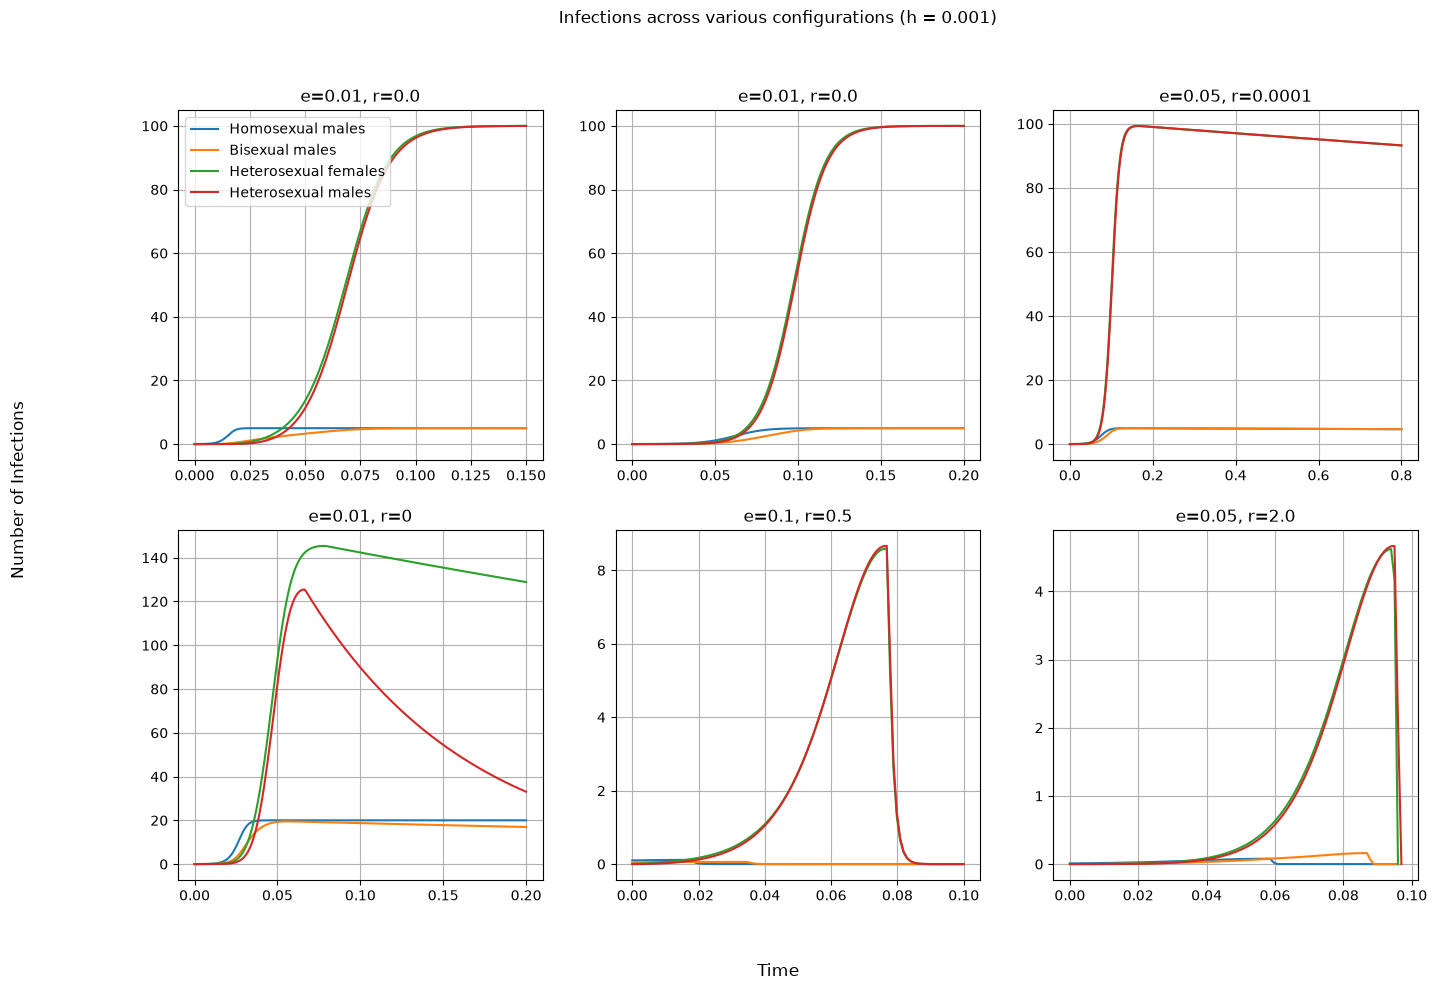

In [252]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
labels = ['Homosexual males', 'Bisexual males', 'Heterosexual females', 'Heterosexual males']

for ax, coeffs, start_pops, start_infecs, death_coeff, end, e_val in zip(
    axes.flat, coeffs_list, pops_list, start_infecs_list, death_coeff_list, end_times, e_list):
    step_size = 0.001
    data = fwd_euler_popdeaths(start_infecs, start_pops, coeffs, step_size, end, e_val, True, death_coeff)[0]
    
    timestamps = np.linspace(0, end, len(data))
    
    ax.plot(timestamps, data, label=labels)
    ax.set_title(f'e={e_val}, r={death_coeff[0]}')
    ax.grid(True)

fig.suptitle('Infections across various configurations (h = 0.001)')
axes[0, 0].legend()
fig.supxlabel('Time')
fig.supylabel('Number of Infections')
plt.show()

Finally, we do the same computations but for a step size of h = 0.001 instead of h = 0.00001. Whereas previously this large of a step size was inaccurate, but still generally similar to reality, now it is completely wrong. We obtain nonsensical values. This is because a large step size cannot handle the peak points well. We can conclude that the forward Euler step size needs to be much smaller when we are dealing with sensitive problems with complex shapes. Runge-Kutta 4 would be able to handle this much better, but would require a population update 4 times per step, meaning it would become much slower. However, since Runge-Kutta is more stable, it would be able to use a much larger step size, so is likely still faster than forward Euler.